# β Pictoris: a reproducible detection case study

In [1]:
%matplotlib inline

# Import analysis and plotting tools and record the package version.
import os
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import nahiku
from nahiku import Nahiku
print(f"Nāhiku {nahiku.__version__}")

# Set plot resolution and simplify the axes borders.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/tmp/nahiku-02/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Nāhiku 0.2.0


## 1. Load the fixed observation with Lightkurve

TESS sector 6 contains the event near BTJD 1486.4 discussed by [Zieba et al. (2019)](https://arxiv.org/abs/1903.11071). Pulsations must be treated before searching for slower dips.

The default loading path uses **Lightkurve** and MAST. A fixed CSV subset of the observations supports an offline run (`NAHIKU_OFFLINE=1`). Install the package’s `data` and `docs` extras. This example illustrates detection methods; it does not establish the physical origin of detected features.

Prewhitening offers two methods: `method="balmung"` is the default, using an unweighted joint sinusoid fit and a threshold fixed from the initial amplitude spectrum. `method="weighted"` uses measurement errors, local frequency refinement, and a threshold recomputed from the residual spectrum; it also supports `fit_mask` to protect specified samples. This notebook selects `"weighted"` for uncertainty-weighted pulsation fitting. Both methods preserve the input continuum, retain diagnostics, and record their name in `result.method` and the processing history. Balmung's frequency bounds select the initial peak; its unconstrained fit may refine outside that range.

 The observation manifest records the mission, pipeline, cadence, quarter or sector, product URI, and SHA-256 checksum. We use PDCSAP flux with Lightkurve’s default quality mask, reject invalid values, and normalize by the selected window’s median. BKJD is BJD − 2454833; BTJD is BJD − 2457000. Neither is a sample index.

tess2018349182500-s0006-0000000270577175-0126-s_lc.fits 4306 valid observations


/tmp/nahiku-02/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


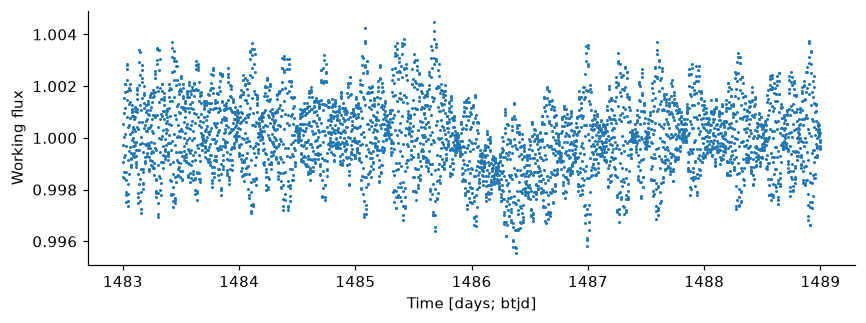

In [2]:
# Load archive tools and checksum utilities for observation provenance.
import hashlib
import lightkurve as lk
from astropy.time import Time

# Run from examples/ or the repository root. No source-path modification is needed.
data_dir = Path("data") if Path("data/beta_pic.json").exists() else Path("examples/data")

# Read the fixed observation selection and choose the data source and cache.
manifest = json.loads((data_dir / "beta_pic.json").read_text())
OFFLINE = os.environ.get("NAHIKU_OFFLINE", "0") == "1"
cache = Path(os.environ.get("NAHIKU_CACHE", str(Path.home() / ".cache/nahiku")))
if not OFFLINE:
    # Query the archive and require the exact product recorded in the manifest.
    products = lk.search_lightcurve(manifest["target"], **manifest["selection"])
    selected = products[products.table["dataURI"] == manifest["data_uri"]]
    if len(selected) != 1:
        raise RuntimeError("The frozen product is unavailable; inspect the archive selection")
    # Download quality-filtered observations and verify the product checksum.
    lightcurve = selected.download(download_dir=str(cache), quality_bitmask="default")
    digest = hashlib.sha256(Path(lightcurve.filename).read_bytes()).hexdigest()
    if digest != manifest["sha256"]:
        raise RuntimeError("Archive product changed; review provenance before updating the manifest")
    # Restrict the analysis to the recorded time window before conversion.
    lo, hi = manifest["window_days"]
    lightcurve = lightcurve[(lightcurve.time.value >= lo) & (lightcurve.time.value <= hi)]
    raw = Nahiku.from_lightkurve(lightcurve)
else:
    # Verify the local fixture and construct a Lightkurve object for conversion.
    fixture = data_dir / manifest["fixture"]
    assert hashlib.sha256(fixture.read_bytes()).hexdigest() == manifest["fixture_sha256"]
    values = np.genfromtxt(fixture, delimiter=",", names=True)
    lightcurve = lk.LightCurve(time=Time(values["time"], format=manifest["time_format"], scale="tdb"),
                              flux=values["flux"], flux_err=values["flux_err"])
    raw = Nahiku.from_lightkurve(lightcurve, normalize=False)

# Attach the archive selection and checksum to the analysis provenance.
raw.metadata.update(target=manifest["target"], data_uri=manifest["data_uri"],
                    product_sha256=manifest["sha256"], quality_bitmask="default",
                    selection=manifest["selection"], window_days=manifest["window_days"])

# Report the sample count and inspect the observations before preprocessing.
print(manifest["product"], len(raw.time), "valid observations")
raw.plot();

## 2. Remove rapid pulsations before binning

Fit frequencies between 20 and 80 cycles/day at the original two-minute cadence. Removing sinusoids after coarse binning would alias these pulsations. This example removes at most 60 components and stops earlier when the peak/median amplitude ratio is below four. The fit uses the entire selected window, without masking the known dip. This is not a reproduction of the published full-baseline frequency analysis.

Inspect the stopping reason. Reaching the component limit does not establish complete pulsation removal. Measurement errors propagated below exclude uncertainty in the estimated pulsations.

Components: 60 stop: component_limit


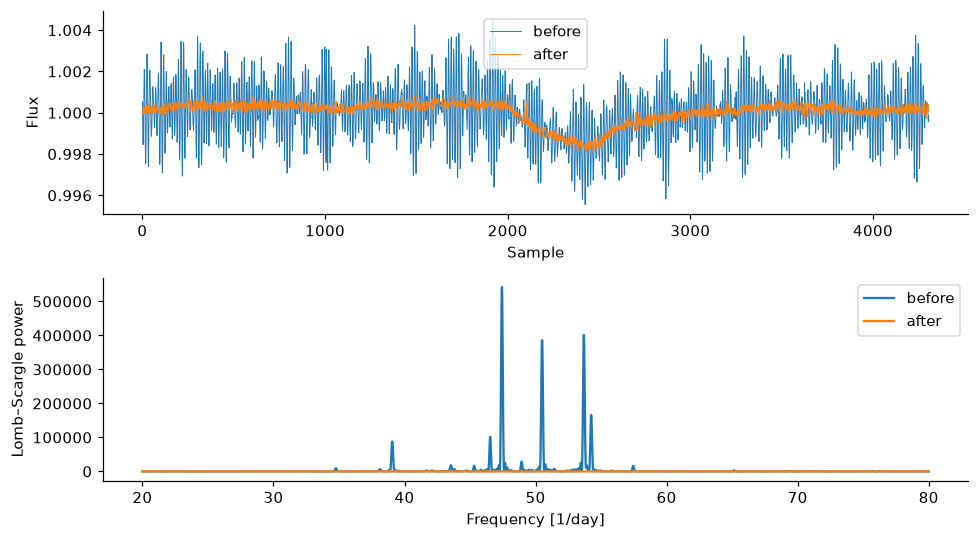

In [3]:
# Fit and remove rapid pulsations at the original observation cadence.
prewhitening = raw.prewhiten(method="weighted", fmin=20, fmax=80, max_components=60, minimum_snr=4)

# Inspect the component count, stopping reason, and residual spectrum.
print("Components:", len(prewhitening.frequencies), "stop:", prewhitening.stopping_reason)
prewhitening.plot();

### Check dip preservation with an injection

Repeat preprocessing after injecting a small dip away from the reference event. Compare residual differences with the injected signal. This injection test checks one profile and cannot establish recovery across all dip shapes or frequencies.

Recovered injected-profile projection: 0.9999927188395312


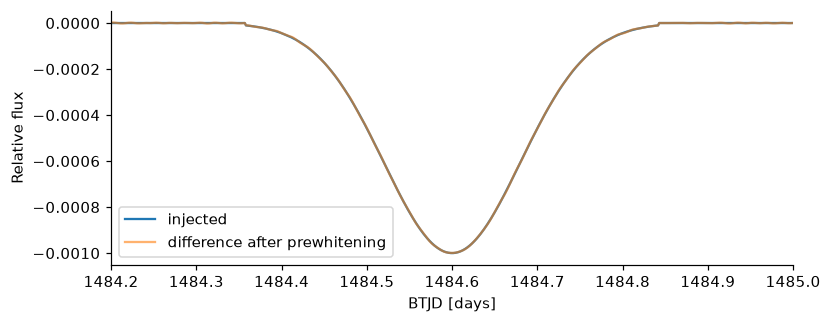

In [4]:
# Start from the original observations and inject a dip away from the reference event.
probe = raw.copy().reset()
injected = probe.inject_anomaly(center=1484.6, width=0.08, depth=0.001, shape="gaussian")

# Apply the same preprocessing to isolate its effect on the injected signal.
probe.prewhiten(method="weighted", fmin=20, fmax=80, max_components=60, minimum_snr=4)

# Project the residual difference onto the injected profile to measure its recovery.
recovered = probe.flux - raw.flux
recovered_scale = float(recovered @ injected / (injected @ injected))
print("Recovered injected-profile projection:", recovered_scale)

# Compare the injected signal with its contribution after prewhitening.
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(raw.time, injected, label="injected")
ax.plot(raw.time, recovered, label="difference after prewhitening", alpha=.6)
ax.set(xlim=(1484.2, 1485), xlabel="BTJD [days]", ylabel="Relative flux")
ax.legend();

## 3. Bin and fit the baseline

Inverse-variance binning at 0.02 days reduces the number of samples for exact Gaussian process (GP) fitting. Errors assume independent samples; residual correlations can invalidate that approximation. The binned object retains provenance and source-bin membership, while `raw` retains the full-cadence observations. A squared-exponential GP models the baseline without requiring a pulsation or rotation period. The synthetic example demonstrates the quasi-periodic kernel.

The RBF length scale is constrained to 1–6 days to describe a smooth baseline rather than short dip structure. This is an explicit modeling assumption for this focused window. The additional noise standard deviation starts at 0.3 in standardized flux units and is optimized jointly with the kernel. The fit retains the parameter state with the lowest evaluated training loss. Inspect the stopping reason: reaching the iteration limit does not establish convergence.

GP samples: 300 stop: iteration_limit
Learned additional noise variance: 0.09426260022586272
Final training loss: 0.4047710139946499


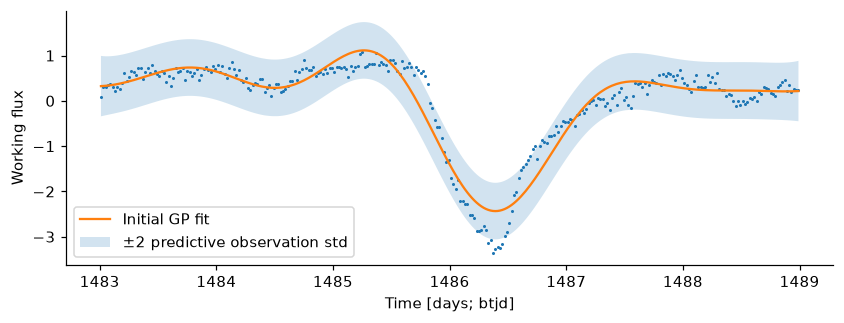

In [5]:
# Bin the prewhitened data and express flux and errors in standardized units.
lc = raw.bin(0.02).standardize()

# Restrict the baseline to smooth variability on timescales of at least one day.
import gpytorch
def baseline_kernel():
    kernel = gpytorch.kernels.ScaleKernel(
        gpytorch.kernels.RBFKernel(
            lengthscale_constraint=gpytorch.constraints.Interval(1.0, 6.0)
        )
    )
    kernel.base_kernel.lengthscale = 1.5
    return kernel

# Optimize the additional noise jointly with the kernel and retain the best state.
fit_settings = dict(noise=0.3, iterations=1000, learning_rate=0.05,
                    patience=30, save_state="best")
lc.fit_gp(kernel=baseline_kernel(), **fit_settings)
diagnostics = lc.fit_diagnostics
print("GP samples:", len(lc.time), "stop:", diagnostics["stopping_reason"])
print("Learned additional noise variance:", diagnostics["noise_after_adjustment"])
print("Final training loss:", diagnostics["losses"][-1])

# Inspect the initial prediction and its observation uncertainty before searching.
mean, std = lc.predict(include_noise=True)
fig, ax = lc.plot()
ax.plot(lc.time, mean, label="Initial GP fit")
ax.fill_between(lc.time, mean - 2*std, mean + 2*std, alpha=0.2,
                label="±2 predictive observation std")
ax.legend();

## 4. Run and compare both searches

Both searches use the same fitted GP and working data. Greedy search seeds negative posterior residuals at four residual standard deviations and grows intervals while the retained-data marginal likelihood improves. Exhaustive search tests windows of 3–60 samples, approximately 0.06–1.2 days at this binning, with a conditional p-value threshold of 10⁻²⁰. A smaller p-value threshold is more restrictive. Its scores account for conditional covariance within a window, but not repeated testing or fitted-hyperparameter uncertainty.

The baseline constraint and search settings were selected using this known-event window. They have not been independently calibrated. Neither search is restricted to a predefined event time or forced to return one event.

Greedy events: [{'start': 140, 'stop': 197, 'time_start': 1485.8117095144312, 'time_last': 1486.931142407726}]
Exhaustive events: [{'start': 117, 'stop': 210, 'time_start': 1485.351288218251, 'time_last': 1487.1915573453582}]


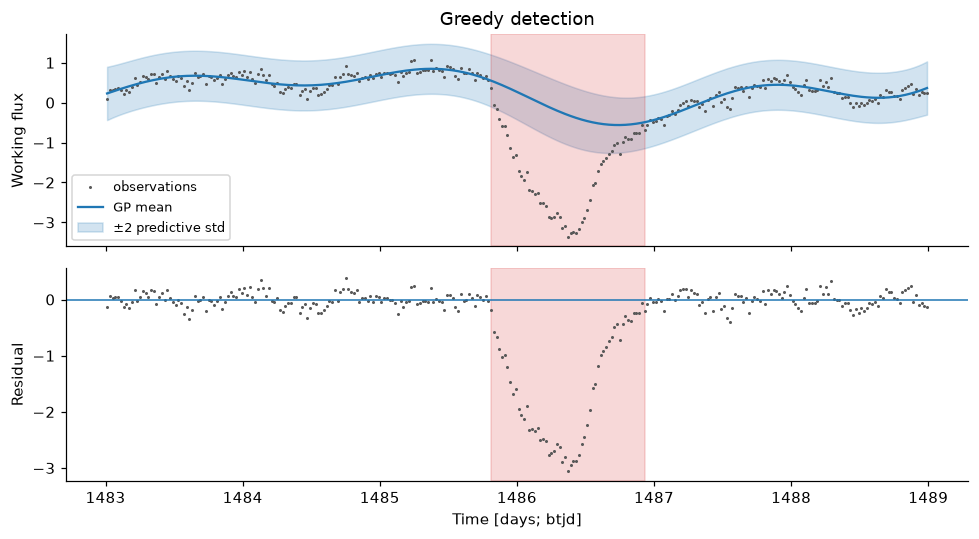

In [6]:
# Seed sustained negative residuals and grow the interval using retained-data MLL.
greedy_settings = dict(sigma=4, seed_statistic="residual", growth="metric",
                       growth_metric="mll", direction="negative", gap_factor=5,
                       backend="torch")
greedy = lc.greedy_search(**greedy_settings)

# Include windows long enough to exclude the broad dip, not only its deepest points.
exhaustive_settings = dict(min_points=3, max_points=60, step=3, size_step=3,
                           threshold=1e-20, direction="negative", gap_factor=5,
                           backend="torch")
exhaustive = lc.exhaustive_search(**exhaustive_settings)

# Compare the detected intervals; conditional exhaustive plots follow below.
greedy.plot();
print("Greedy events:", greedy.events)
print("Exhaustive events:", exhaustive.events)

The upper panel shows the GP prediction conditioned on observations outside all detected intervals. In the lower panel, each colored curve excludes only its own candidate window. Matching dots identify the excluded observations, and bands show ±2 predictive observation standard deviations. By default, each merged event is represented by its strongest selected candidate, with ties resolved by sample bounds. Use `selection="all"` to show all selected windows, including overlaps. A merged event may span several scored windows. Joint scores use correlations between observations as well as the pointwise uncertainties shown in the bands.

`event_index` selects a merged event by its zero-based index and plots its representative candidate's GP across the full light curve. Other detections remain in the conditioning data. The stored predictions include any candidate-specific refits, so plotting requires no further optimization or live GP. Use `kind="residuals"` to inspect residuals after excluding all detected intervals. Numerical exports include the conditional distributions.

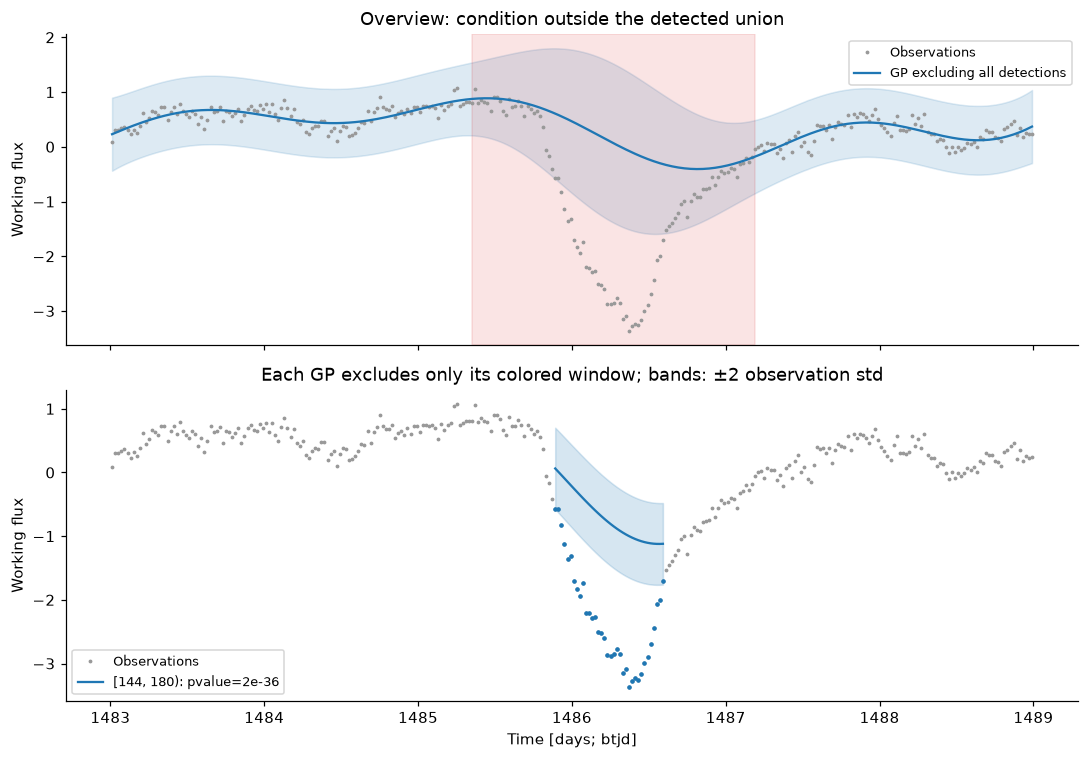

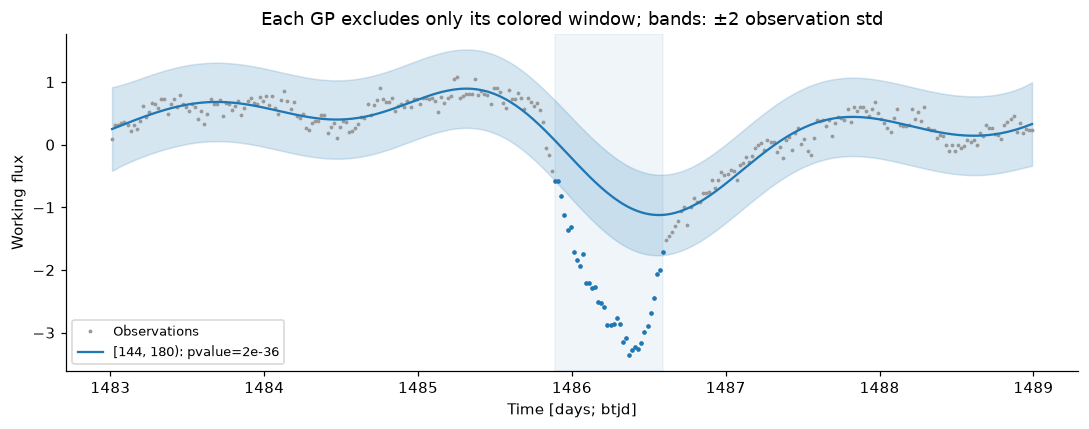

In [7]:
# Inspect the scored conditional fit for one representative window per event.
exhaustive.plot(kind="conditional");

# Plot one candidate's GP over the full light curve, excluding only that window.
if exhaustive.intervals:
    exhaustive.plot(kind="conditional", event_index=0);

# All overlapping selected windows remain accessible with selection="all".
# exhaustive.plot(kind="conditional", selection="all");

Shaded regions combine selected candidate intervals. Their boundaries are detection boundaries, not measured physical ingress or egress times. The overview GP excludes all detected samples; each exhaustive conditional prediction excludes only its own candidate window. Additional detections may arise from residual variability, preprocessing, or instrumental effects. Without a complete truth catalogue, precision and recall are not assigned to these stellar detections.

## 5. Save the run and reproduce figure candidates

The figure gallery uses the exported arrays and configuration to produce PDF and PNG figures showing fits, residuals, event close-ups, and comparisons between methods.

In [8]:
# Choose a configurable directory for numerical results.
output = Path(os.environ.get("NAHIKU_OUTPUT", "outputs"))

# Export search predictions and observation provenance.
greedy.export(output / "beta_pic_greedy")
exhaustive.export(output / "beta_pic_exhaustive")
lc.export(output / "beta_pic_lightcurve")

# Save the full-cadence prewhitening diagnostics for figure reproduction.
np.savez_compressed(output / "beta_pic_prewhitening.npz", time=raw.time, original=raw.original_flux,
                    residuals=prewhitening.residuals, model=prewhitening.model,
                    frequency=prewhitening.frequency_grid, power_before=prewhitening.power_before,
                    power_after=prewhitening.power_after, removed_frequencies=prewhitening.frequencies)
print("Saved results to", output)

Saved results to /mnt/lustre/koa/koastore/sadow_group/personal/linneamw/research/dipper_detection/codex/results


## 6. Optional full-data recipe

Keep the switch below disabled to run the focused example. Enable it to query the full archive selection. Product availability can change, downloads can be large, and dense GP fitting has cubic cost in sample count. Analyze each observation and each gap-separated segment independently; do not stitch all sectors/quarters into a single covariance matrix. Save a new manifest for each full-data run. The loop uses the same settings as the focused example; validate them before applying them to other epochs.

In [9]:
# Enable archive-wide processing only when a full-data analysis is intended.
RUN_FULL_DATA = False
if RUN_FULL_DATA:
    # Query all epochs matching the remaining mission and pipeline settings.
    selection = {k: v for k, v in manifest["selection"].items() if k not in ("quarter", "sector")}
    # Retrieve all products matching the selected epochs.
    products = lk.search_lightcurve(manifest["target"], **selection)
    full_manifest = {"target": manifest["target"], "products": []}
    for index in range(len(products)):
        # Download one product and convert its valid observations.
        observation = products[index].download(download_dir=str(cache), quality_bitmask="default")
        series = Nahiku.from_lightkurve(observation)
        # Split each observation at substantial time gaps before fitting.
        breaks = np.flatnonzero(np.diff(series.time) > 5*np.median(np.diff(series.time))) + 1
        for segment_id, indices in enumerate(np.split(np.arange(len(series.time)), breaks)):
            if len(indices) < 30:
                continue
            # Limit each dense fit to a bounded time window, with overlap for edge checks.
            window = 6.0
            for start in np.arange(series.time[indices[0]], series.time[indices[-1]], window*0.8):
                keep = indices[(series.time[indices] >= start) & (series.time[indices] < start+window)]
                if len(keep) < 30:
                    continue
                # Construct an independent series for this bounded time window.
                segment = Nahiku(series.time[keep], series.flux[keep], series.flux_err[keep], series.metadata)
                # Remove pulsations before binning to avoid cadence aliasing.
                segment.prewhiten(method="weighted", fmin=20, fmax=80, max_components=60, minimum_snr=4)
                segment = segment.bin(0.02)
                if len(segment.time) <= 15:
                    continue
                # Fit the baseline using the settings from the focused analysis.
                segment.standardize().fit_gp(kernel=baseline_kernel(), **fit_settings)
                # Run both searches and save each window under a distinct name.
                key = f"full_{index}_{segment_id}_{start:.4f}"
                segment.greedy_search(**greedy_settings).export(output / (key+"_greedy"))
                segment.exhaustive_search(**exhaustive_settings).export(output / (key+"_exhaustive"))
        # Record each downloaded product and its checksum.
        full_manifest["products"].append({"uri": str(products.table["dataURI"][index]),
            "sha256": hashlib.sha256(Path(observation.filename).read_bytes()).hexdigest()})
    # Save the archive manifest alongside the per-window results.
    (output / "full_archive_manifest.json").write_text(json.dumps(full_manifest, indent=2))

## Interpret the result

Both searches identify one merged event around the prominent dip near BTJD 1486.4, with no additional events elsewhere in this focused window. Their boundaries differ because greedy search grows from residuals whereas exhaustive search merges independently scored windows. These are detection intervals, not measurements of physical ingress or egress. The settings were selected on this example; the absence of other detections does not establish a survey-wide false-positive rate.

Overlapping analysis windows can contain the same physical event. Match detections by observation time before counting events. Review boundary detections and quality flags. Cite NASA Kepler/TESS, MAST, Lightkurve, and the source paper linked above; see the citation guide for software references.

Consult the API reference for parameter and return-value details.